       HASIL EKSPERIMEN SKALA KONKURENSI
Batas Konkurensi:  1 | Waktu Total: 3.5653 detik
Batas Konkurensi:  3 | Waktu Total: 1.4519 detik
Batas Konkurensi:  5 | Waktu Total: 0.9999 detik
Batas Konkurensi: 10 | Waktu Total: 0.7199 detik
Batas Konkurensi: 20 | Waktu Total: 0.7628 detik
Pengujian selesai.


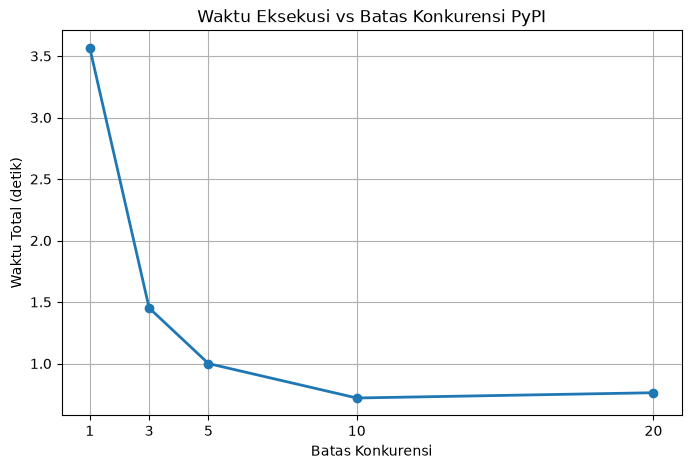

In [13]:

import time
import requests
import concurrent.futures
import matplotlib.pyplot as plt

daftar_paket_banyak = [
    "aiohttp", "httpx", "rich", "typer", "streamlit",
    "gradio", "dash", "bokeh", "altair", "polars",
    "openpyxl", "xlsxwriter", "lxml", "scrapy", "selenium",
    "pymongo", "redis", "psycopg2-binary", "alembic", "loguru",
    "colorama", "pytest-cov", "coverage", "isort", "mypy"
]

def cek_pypi(nama_paket):
    url = f"https://pypi.org/pypi/{nama_paket}/json"

    try:
        response = requests.get(url, timeout=5)
        if response.status_code == 200:
            return f"Sukses: {nama_paket}"
    except Exception:
        pass

    return f"Gagal: {nama_paket}"


def ukur_waktu_konkurensi(batas_konkurensi, daftar_paket):
    mulai = time.perf_counter()

    with concurrent.futures.ThreadPoolExecutor(
        max_workers=batas_konkurensi
    ) as executor:
        list(executor.map(cek_pypi, daftar_paket))

    selesai = time.perf_counter()
    return selesai - mulai


if __name__ == "__main__":
    batas_konkurensi_list = [1, 3, 5, 10, 20]
    waktu_eksekusi = {}

    print("=" * 52)
    print("       HASIL EKSPERIMEN SKALA KONKURENSI")
    print("=" * 52)

    for batas in batas_konkurensi_list:
        durasi = ukur_waktu_konkurensi(
            batas, daftar_paket_banyak
        )
        waktu_eksekusi[batas] = durasi

        print(
            f"Batas Konkurensi: {batas:2d} "
            f"| Waktu Total: {durasi:.4f} detik"
        )

    print("=" * 52)
    print("Pengujian selesai.")

    x = list(waktu_eksekusi.keys())
    y = list(waktu_eksekusi.values())

    plt.figure(figsize=(8, 5))
    plt.plot(x, y, marker="o", linestyle="-", linewidth=2)
    plt.xlabel("Batas Konkurensi")
    plt.ylabel("Waktu Total (detik)")
    plt.title("Waktu Eksekusi vs Batas Konkurensi PyPI")
    plt.xticks(batas_konkurensi_list)
    plt.grid(True)
    plt.show()


# Analisis Nomor 1
1. Penambahan batas konkurensi mulai memberikan manfaat yang semakin kecil ketika peningkatan jumlah thread tidak lagi mengurangi waktu eksekusi secara signifikan. Pada pengujian pengambilan data dari API PyPI, penggunaan 3 hingga 5 thread dapat mempercepat proses dibandingkan hanya menggunakan 1 thread. Namun, ketika batas konkurensi ditingkatkan dari 10 menjadi 20 thread, peningkatan performa cenderung lebih kecil atau hampir tidak berubah. Kondisi ini disebut diminishing returns, yaitu ketika penambahan konkurensi tidak lagi memberikan peningkatan kinerja yang sebanding.
2. Hukum Amdahl menjelaskan bahwa peningkatan performa melalui penambahan thread memiliki batas tertentu karena tidak semua proses dapat dijalankan secara paralel. Pada pengujian pengambilan data dari API PyPI, penambahan thread dapat mempercepat proses, tetapi jika jumlahnya terus ditingkatkan, manfaatnya akan semakin kecil akibat latensi jaringan dan overhead pengelolaan thread. Kondisi ini disebut diminishing returns, yaitu ketika penambahan konkurensi tidak lagi memberikan peningkatan kecepatan yang sebanding.

In [15]:

import asyncio
import time
import math

async def pakai_asyncio_sleep():
    print("Mulai asyncio.sleep()")
    await asyncio.sleep(2)
    print("Selesai asyncio.sleep()")

async def pakai_time_sleep():
    print("Mulai time.sleep() (Blocking)")
    time.sleep(2)
    print("Selesai time.sleep()")

async def pakai_cpu_bound():
    print("Mulai CPU-bound (Perhitungan)")
    hasil = 0
    for i in range(5_000_000):
        hasil += i * i
    print("Selesai CPU-bound")

async def pengukur():
    for i in range(1, 7):
        await asyncio.sleep(0.5)
        print(f"-> [Pengukur] Berjalan pada detik ke-{i * 0.5:.1f}")

async def main():
    print("--- MULAI PERCOBAAN ---")
    mulai = time.perf_counter()

    await asyncio.gather(
        pakai_asyncio_sleep(),
        pakai_time_sleep(),
        pakai_cpu_bound(),
        pengukur()
    )

    print(f"--- SELESAI: {time.perf_counter() - mulai:.2f} detik ---")

await main()


--- MULAI PERCOBAAN ---
Mulai asyncio.sleep()
Mulai time.sleep() (Blocking)
Selesai time.sleep()
Mulai CPU-bound (Perhitungan)
Selesai CPU-bound
Selesai asyncio.sleep()
-> [Pengukur] Berjalan pada detik ke-0.5
-> [Pengukur] Berjalan pada detik ke-1.0
-> [Pengukur] Berjalan pada detik ke-1.5
-> [Pengukur] Berjalan pada detik ke-2.0
-> [Pengukur] Berjalan pada detik ke-2.5
-> [Pengukur] Berjalan pada detik ke-3.0
--- SELESAI: 5.75 detik ---


# Analisis Nomor 2
A. Pengaruh asyncio.sleep()
asyncio.sleep() memungkinkan event loop menjalankan coroutine lain selama proses menunggu. Dengan demikian, tugas asynchronous dapat berjalan secara bergantian tanpa harus menghentikan seluruh proses program.
B. Pengaruh time.sleep()
time.sleep() memblokir event loop selama proses penundaan berlangsung. Akibatnya, coroutine pengukur tidak dapat berjalan sesuai interval yang ditentukan dan harus menunggu hingga proses blocking selesai.
C. Pengaruh Operasi CPU-bound
Operasi CPU-bound melakukan perhitungan secara terus-menerus tanpa menggunakan await. Hal ini menyebabkan event loop tidak dapat menjalankan coroutine lain sampai perhitungan selesai. Semakin berat perhitungan yang dilakukan, semakin besar kemungkinan coroutine lain mengalami keterlambatan.

In [16]:

import asyncio
import random

JUMLAH_CONSUMER = 3

async def producer(queue, jumlah_item):
    for i in range(jumlah_item):
        item = f"item-{i}"
        prioritas = random.randint(1, 3)

        await asyncio.sleep(random.uniform(0.05, 0.15))
        await queue.put((prioritas, i, item))

        print(f"[Producer] Menghasilkan: {item} "
              f"(Prioritas {prioritas})")

    for i in range(JUMLAH_CONSUMER):
        await queue.put((999, i, None))


async def consumer(queue, nama):
    while True:
        prioritas, nomor, item = await queue.get()

        if item is None:
            queue.task_done()
            break

        await asyncio.sleep(random.uniform(0.1, 0.2))
        print(f"[{nama}] Memproses: {item} "
              f"(Prioritas {prioritas})")

        queue.task_done()


async def main():
    queue = asyncio.PriorityQueue(maxsize=5)

    await asyncio.gather(
        producer(queue, 8),
        *[
            consumer(queue, f"Consumer-{i}")
            for i in range(JUMLAH_CONSUMER)
        ]
    )

    print("\nSemua item selesai diproses.")

await main()


[Producer] Menghasilkan: item-0 (Prioritas 1)
[Producer] Menghasilkan: item-1 (Prioritas 2)
[Consumer-0] Memproses: item-0 (Prioritas 1)
[Producer] Menghasilkan: item-2 (Prioritas 1)
[Producer] Menghasilkan: item-3 (Prioritas 2)
[Consumer-0] Memproses: item-1 (Prioritas 2)
[Producer] Menghasilkan: item-4 (Prioritas 3)
[Consumer-2] Memproses: item-2 (Prioritas 1)
[Producer] Menghasilkan: item-5 (Prioritas 3)
[Consumer-1] Memproses: item-3 (Prioritas 2)
[Consumer-0] Memproses: item-4 (Prioritas 3)
[Producer] Menghasilkan: item-6 (Prioritas 3)
[Consumer-2] Memproses: item-5 (Prioritas 3)
[Producer] Menghasilkan: item-7 (Prioritas 1)
[Consumer-1] Memproses: item-6 (Prioritas 3)
[Consumer-0] Memproses: item-7 (Prioritas 1)

Semua item selesai diproses.


# Analisa Nomor 3
A. Penerapan prioritas
asyncio.PriorityQueue digunakan untuk mengurutkan item berdasarkan nilai prioritas. Prioritas 1 merupakan prioritas tertinggi, sedangkan prioritas 3 merupakan prioritas terendah.
B. Proses producer dan consumer
Producer menghasilkan item dengan prioritas acak antara 1 hingga 3. Ketiga consumer mengambil item dari antrean berdasarkan prioritas yang tersedia. Jika beberapa item memiliki prioritas sama, nomor urut digunakan untuk menentukan urutan pengambilan.

# 4 Refleksi Singkat
threading cocok digunakan untuk menangani tugas I/O-bound karena beberapa thread dapat menunggu proses input/output secara bersamaan. multiprocessing lebih sesuai untuk tugas CPU-bound karena dapat menjalankan proses secara paralel dengan memanfaatkan beberapa core CPU, tetapi membutuhkan sumber daya lebih besar. Sementara itu, asyncio efektif untuk menangani banyak tugas I/O-bound menggunakan coroutine dan event loop tanpa harus membuat banyak thread.
Dari segi kemudahan, threading relatif mudah dipahami, sedangkan multiprocessing membutuhkan pengaturan proses yang lebih kompleks. asyncio memerlukan pemahaman tentang async dan await, tetapi dapat mengelola banyak tugas secara efisien. Oleh karena itu, pemilihan metode konkurensi perlu disesuaikan dengan jenis pekerjaan agar program berjalan lebih optimal.